#### 1.Setup

In [428]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [429]:
from dotenv import load_dotenv
import os

load_dotenv(override=True)

api_key = os.getenv("GROQ_API_KEY")

if api_key:
    print("Groq API key loaded successfully!")
else:
    print("API key not found. Check your .env file.")

Groq API key loaded successfully!


In [430]:
from pathlib import Path
from dotenv import load_dotenv
import os

env_path = Path("/Users/laltusingh/Desktop/LangGraph-Course/.env")

print("File exists:", env_path.exists())

load_dotenv(dotenv_path=env_path, override=True)

print("GROQ_API_KEY exists:", "GROQ_API_KEY" in os.environ)
print("API key is empty:", not bool(os.getenv("GROQ_API_KEY")))

File exists: True
GROQ_API_KEY exists: True
API key is empty: False


In [431]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b")

In [432]:
res = llm.invoke("hello, I am Laltu")
res.content

'Hello Laltu! Nice to meet you. How can I help you today?'

#### 2. State - Global State to pass the data between all the nodes

In [433]:
from pydantic import BaseModel

class UserState(BaseModel):
    name: str = ""
    email: str = ""
    age: int = 0

state = UserState(name = "Naveen")

In [434]:
state

UserState(name='Naveen', email='', age=0)

#### 2.1 Building the Graph using LangGraph

In [435]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class MyState(BaseModel):
    message: str = ""
    isPassed: bool = False

def greet(state:MyState):
    "I am greet node..."
    state.isPassed = True
    state.message = " Good Morning!!"
    # print(state.messages)
    return state

graph = StateGraph(MyState)
graph.add_node("Welcome", greet)

graph.add_edge(START, "Welcome")
graph.add_edge("Welcome", END)

final_graph = graph.compile()

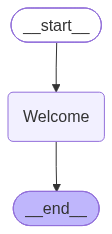

In [436]:
final_graph

In [437]:
res = final_graph.invoke({"messages": "Hello Naveen Singh"})

In [438]:
res

{'message': ' Good Morning!!', 'isPassed': True}

#### 2.2 Multi Node Graph

In [439]:
from random import randint

class ReviewState(BaseModel):
    text: str = ""
    score: int = 0
    comments: str = ""

def score(state:ReviewState) -> ReviewState:
    state.score = randint(1, 10)
    return state

def commenter(state:ReviewState) -> ReviewState:
    if state.score > 5:
        state.comments = "Well Done"
    else:
        state.comments = "Need improvement"
    return  state
graph = StateGraph(ReviewState)
graph.add_node("score", score)
graph.add_node("commenter", commenter)

graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)

final_graph_2 = graph.compile()

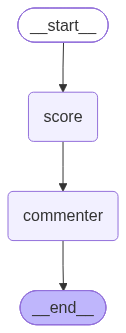

In [440]:
final_graph_2

In [441]:
res_2 = final_graph_2.invoke({})

In [442]:
res_2

{'text': '', 'score': 9, 'comments': 'Well Done'}

#### 3. Add_messages reducer - for chat history

In [443]:
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage
from typing import Annotated

class ChatState(BaseModel):
    messages: Annotated[list, add_messages] = []

def Chat_bot(state:ChatState):
    print(state.messages)

graph = StateGraph(ChatState)

graph.add_node("chat_bot", Chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final_graph_3 = graph.compile()

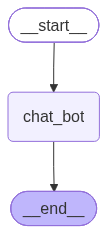

In [444]:
final_graph_3

In [445]:
# res_3 = final_graph_3.invoke({"messages": [ {"role":"user", "content": "Hello, how are u??"} ] })
# If we use HumanMessage the also the result will be same.
# Need to import HumanMessages, AIMessages
# from langchain_core.messages import HumanMessage, AIMessage -> Like this
res_3 = final_graph_3.invoke({"messages": [HumanMessage(content = "hello Laltu Ji")]})

[HumanMessage(content='hello Laltu Ji', additional_kwargs={}, response_metadata={}, id='f82b2d9d-9321-443a-aade-c27082141f2a')]


#### 3.1 Create Custome Reducers

In [446]:
from langgraph.graph.message  import add_messages
from langchain_core.messages import HumanMessage, AIMessage
from typing import Annotated

def custom_reducer(existing: list, new:list):
    all_msg = existing + new
    return all_msg[-2:]

def isPositive(existing: int, new:int):
    if new <0:
        return 0
    return new

class ChatState(BaseModel):
    messages: Annotated[list, custom_reducer] = []
    count: Annotated[int, isPositive] = 0

def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    state.count = -10
    return state

graph = StateGraph(ChatState)

graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final_graph = graph.compile()

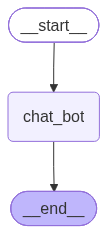

In [447]:
final_graph

In [448]:
res = final_graph.invoke({"messages": [HumanMessage(content = "Hello, How are you?")]})

In [449]:
res

{'messages': [HumanMessage(content='Hello, How are you?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Hello! I’m doing great, thank you for asking. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hello, How are you?" The assistant should respond politely. No disallowed content. So just respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 77, 'total_tokens': 132, 'completion_time': 0.114023475, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.013923135, 'prompt_tokens_details': None, 'queue_time': 0.410336193, 'total_time': 0.12794661}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_f640395b96', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1779e-01da-7703-8602-a4e2a2fdf340-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 55, 'total_

#### 4. Conditional Routing

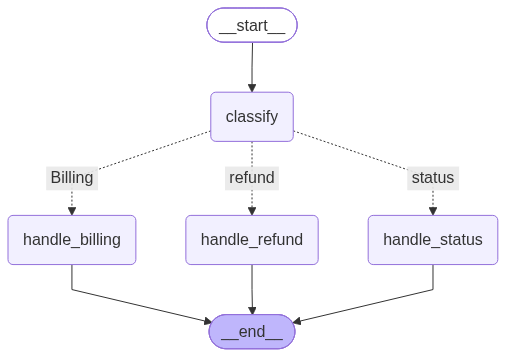

In [450]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Literal

class TicketState(BaseModel):
    issue:str = ""
    category:str = ""
    response:str = ""

def classify(state:TicketState)-> TicketState:
    issue = state.issue.lower()
    if "payment" in issue or "amount" in issue:
        state.category ="billing"

    elif "refund" in issue or "cancel" in issue:
        state.category = "refund"

    else:
        state.category = "status"
    return state

def handle_billing(state:TicketState)-> TicketState:
    print('Billing Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_refund(state:TicketState) -> TicketState:
    print('Refund Related Issue')
    state.response = f"Issue Resolved for {state.category}"
    return state

def handle_status(state:TicketState)-> TicketState:
    print("Status Related Issue")
    state.response = f"Issue resolved for {state.category}"
    return state

def router_logic(state:TicketState) -> Literal["billing", "refund", "status"]:
    return state.category

graph = StateGraph(TicketState)
graph.add_node("classify", classify)
graph.add_node("handle_billing", handle_billing)
graph.add_node("handle_refund", handle_refund)
graph.add_node("handle_status", handle_status)

graph.add_edge(START, "classify")
graph.add_conditional_edges("classify", router_logic,
                            {"Billing": "handle_billing",
                             "status": "handle_status",
                             "refund": "handle_refund"}
                             )
graph.add_edge("handle_billing", END)
graph.add_edge("handle_refund", END)
graph.add_edge("handle_status", END)

final_graph = graph.compile()
final_graph


In [451]:
res_4 = final_graph.invoke({"issue": "I am waiting for my refund"})

Refund Related Issue


In [452]:
res_4

{'issue': 'I am waiting for my refund',
 'category': 'refund',
 'response': 'Issue Resolved for refund'}

#### 5. Memomry Checkpointer

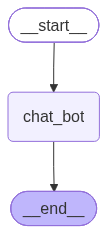

In [453]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from typing import Annotated
from langgraph.checkpoint.memory import InMemorySaver

class ChatState(BaseModel):
    messages: Annotated[list, add_messages] = []
    # count: int = 0

def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    # state.count = -10
    return state

graph =StateGraph(ChatState)

graph.add_node("chat_bot",chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)
memory = InMemorySaver()
final_graph_5 = graph.compile(checkpointer=memory)

final_graph_5

    

In [454]:
res_5 = final_graph_5.invoke({"messages": [ HumanMessage(content="What is his age??")]},
                             {"configurable": {"thread_id":"asd1"}})
ans = res_5["messages"][-1].content
print(ans)

I’m not sure who you’re referring to. Could you let me know who “he” is, or provide a bit more context? Then I’ll do my best to help!


In [455]:
%pip install langgraph-checkpoint-sqlite


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [456]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

connection = sqlite3.connect("db.sqlite3", check_same_thread=False)
sql_memory = SqliteSaver(connection)
sql_memory.setup()

In [457]:
sqlite_graph = graph.compile(checkpointer=sql_memory)

In [458]:
res_6 = sqlite_graph.invoke(
    {"messages": 
     [HumanMessage(content= "What is his age??")]
     }, 
     {"configurable":{"thread_id":"asd2"}}
)

ans_1 = res_6["messages"][-1].content
print(ans_1)

Amit Shah was born on 22 October 1964, so on 24 October 2026 he is **62 years old** (he just turned 62 two days ago).


In [459]:
import sqlite3

conn = sqlite3.connect("db.sqlite3")
cur = conn.cursor()
cur.execute("SELECT name, sql FROM sqlite_master WHERE type='table';")
for name, sql in cur.fetchall():
    print(f"--- {name} ---")
    print(sql)
cur.execute("SELECT thread_id, checkpoint_id FROM checkpoints;")
print(cur.fetchall())
conn.close()

--- checkpoints ---
CREATE TABLE checkpoints (
                thread_id TEXT NOT NULL,
                checkpoint_ns TEXT NOT NULL DEFAULT '',
                checkpoint_id TEXT NOT NULL,
                parent_checkpoint_id TEXT,
                type TEXT,
                checkpoint BLOB,
                metadata BLOB,
                PRIMARY KEY (thread_id, checkpoint_ns, checkpoint_id)
            )
--- writes ---
CREATE TABLE writes (
                thread_id TEXT NOT NULL,
                checkpoint_ns TEXT NOT NULL DEFAULT '',
                checkpoint_id TEXT NOT NULL,
                task_id TEXT NOT NULL,
                task_path TEXT NOT NULL DEFAULT '',
                idx INTEGER NOT NULL,
                channel TEXT NOT NULL,
                type TEXT,
                value BLOB,
                PRIMARY KEY (thread_id, checkpoint_ns, checkpoint_id, task_id, idx)
            )
[('asd2', '1f1cf9a1-8b34-6d98-bfff-c084889ec8d6'), ('asd2', '1f1cf9a1-8b37-6b24-8000-d71153a3

In [460]:
import os, sqlite3

DB_PATH = "/Users/laltusingh/Desktop/LangGraph-Course/db.sqlite3"
print("Kernel cwd:", os.getcwd())
print("DB exists:", os.path.exists(DB_PATH))

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()
print("checkpoints rows:", cur.execute("SELECT COUNT(*) FROM checkpoints;").fetchone()[0])
print("writes rows:", cur.execute("SELECT COUNT(*) FROM writes;").fetchone()[0])
conn.close()

Kernel cwd: /Users/laltusingh/Desktop/LangGraph-Course
DB exists: True
checkpoints rows: 103
writes rows: 113


#### 6. Agent and Tools - ToolNodes

In [461]:
from langchain.tools import tool

@tool
def weather_tool(city:str) -> str:
    """
        Get the real time wheather details for any city.
        Args:
        City- city name for the weather details
    """
    ### Real weather API call
    data= {
        "bhopal": "32",
        "delhi": "38",
        "mumbai": "36"
    }

    return data.get(city.lower().strip(), "City not found")
@tool
def calculate(expression:str):
    """
        Execute the math equations: Ex. '4 * 4 -4'
    """
    try:
        return eval(expression)
    except:
        return "Please provide the correct expression"

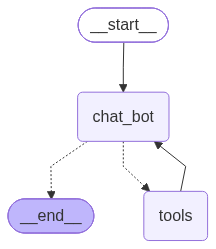

In [462]:
from typing import Annotated
from pydantic import BaseModel
from langchain_core.messages import HumanMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import tools_condition, ToolNode

class AgentState(BaseModel):
    messages: Annotated[list, add_messages]

tools = [weather_tool, calculate]
llm_with_tools = llm.bind_tools(tools)

def chat_bot(state:AgentState):
    res = llm_with_tools.invoke(state.messages)
    # state.messages = [res]
    #Problem: This replaces the entire message history with the latest AI response. 
    # That can remove the original user message and previous tool results, 
    # which the agent needs for a proper conversation.
    # With LangGraph's add_messages reducer, the preferred approach is to 
    # return only the newly generated message.
    return {"messages":[res]}

tool_node = ToolNode(tools)

graph  = StateGraph(AgentState)
graph.add_node("chat_bot", chat_bot)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_bot")
graph.add_conditional_edges("chat_bot", tools_condition)
graph.add_edge("tools", "chat_bot")
# graph.add_edge("chat_bot", END)
# Problem: tools_condition already decides where the graph should go:
# - If the LLM requests a tool, route to "tools".
# - If the LLM doesn't request a tool, route to END.
# The conditional function expects the graph to have a 
# "tools" node and an END route. Adding an unconditional edge 
# from "chat_bot" to END is redundant and can create an unintended routing path.

final_graph_6 = graph.compile(checkpointer= sql_memory)

final_graph_6

In [463]:
res = final_graph_6.invoke(
    {"messages":
        [HumanMessage(content="What is the temperature in Mumbai??")]
        },
     {"configurable":{"thread_id":"asd3"}}
    )

ans_2 = res['messages'][-1].content

In [464]:
res["messages"][-1].content

'I’m sorry—I’m still unable to pull a live weather reading for Mumbai at the moment. The most recent temperature I have on record for the city is **around\u202f34\u202f°C**.\n\nFor the most up‑to‑date temperature, you can check a real‑time weather service such as:\n\n- **Weather.com** – search for “Mumbai, India”  \n- **AccuWeather** – look up Mumbai  \n- **India Meteorological Department (IMD)** website or app  \n\nIf you’d like a short‑term forecast, humidity, or any other weather details for Mumbai, just let me know and I’ll provide the information I have.'

In [465]:
test = llm_with_tools.invoke([
    HumanMessage(content="What is the temperature in Mumbai?")
])

print("Content:", test.content)
print("Tool calls:", test.tool_calls)

Content: 
Tool calls: [{'name': 'weather_tool', 'args': {'city': 'Mumbai'}, 'id': 'fc_c45bf2bc-d9e8-43a5-9209-e4d9efa37818', 'type': 'tool_call'}]


#### 7. Human-In-the-Loop

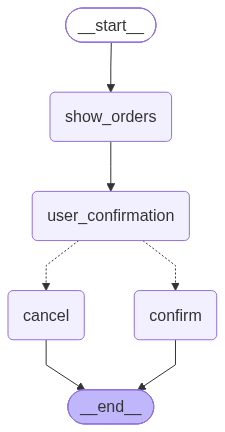

In [466]:
from pydantic import BaseModel
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

class PurchaseState(BaseModel):
    item: str =""
    price: int = 0
    confirmed: bool = False
    status: str = ""

def show_orders(state:PurchaseState) -> PurchaseState:
    print(f"Order summary: Product: {state.item} & Price: {state.price}")
    return state

def user_confirmation(state:PurchaseState)-> PurchaseState:
    response = interrupt(
        {
            "question":f"Confirm your purchase for {state.item} and price is: {state.price}.env. Please reply in Yes or No"
        }
    )
    state.confirmed = response.lower() == "yes"
    return state

def order_cancel(state:PurchaseState) -> PurchaseState:
    print("We have cancelled your order...Thank you")
    return state

def order_confirm(state:PurchaseState)-> PurchaseState:
    print("We have successfully placed you order..")
    return state
# This is not my node    
def router(state:PurchaseState) -> Literal["cancel", "confirm"]:
    if state.confirmed:
        return "conmfirm"
    return "cancel"


graph = StateGraph(PurchaseState)
graph.add_node("show_orders", show_orders)
graph.add_node("user_confirmation",user_confirmation)
graph.add_node("cancel", order_cancel)
graph.add_node("confirm", order_confirm)

graph.add_edge(START, "show_orders")
graph.add_edge("show_orders", "user_confirmation")
graph.add_conditional_edges("user_confirmation", router)
graph.add_edge("cancel", END)
graph.add_edge("confirm", END)

final_graph = graph.compile(checkpointer=InMemorySaver())
final_graph

In [469]:
res = final_graph.invoke(
    {"item":"Samsumg S23", "price":120000},
    {"configurable": {"thread_id":"asd6"}}
)
res["__interrupt__"][0].value["question"]

Order summary: Product: Samsumg S23 & Price: 120000


'Confirm your purchase for Samsumg S23 and price is: 120000.env. Please reply in Yes or No'

In [470]:
res = final_graph.invoke(
    Command(resume= "no"),
    {"configurable":{"thread_id":"asd10"}}

)

We have cancelled your order...Thank you
